# 2b — Socio-economic attribution of criticality, Costa Rica (IDS 2023 quintiles)

## Purpose
Split the criticality of every road produced by
`2_Main_Network_Criticality_Analysis_CR` into the share borne by each **MIDEPLAN
Índice de Desarrollo Social 2023 district quintile**, and map the result.

Nothing expensive from notebook 2 is recomputed: the single-point-of-failure percolation
results are read from disk. What this notebook adds is (a) a demand assignment that keeps
track of *which* quintile each trip comes from and (b) an optional exact re-run that measures
the delay suffered *per quintile*. Both are cached to parquet and paid at most once.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/physical_criticality_results.gpkg` | 5,012 physical roads with SPOF disruption and VHL/PHL/PKL (from notebook 2) |
| `intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg` | the same, per directed edge (9,764 rows) |
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | directed network from 1b, needed to rebuild the graph and the OD demand |
| `input_files/CENTROS_POBLACION/centros_poblados_localidades.shp` | locality points, one per district, with `INEC_PROY` population |
| `input_files/ids_2023_distrital/ids_2023_distrito.shp` | IDS 2023 district polygons, `QUINTIL` I–V |

## Outputs
| File | Description |
|------|-------------|
| `intermediate_results/parquet/socioeconomic/od_quintile_flow.parquet` | cache: 6×6 origin×destination quintile flow tensor per directed edge |
| `intermediate_results/parquet/socioeconomic/quintile_disruption.parquet` | cache: per-quintile delay numerators per physical road (Route B) |
| `intermediate_results/gpkg/travel_disruptions/socioeconomic_criticality.gpkg` | layers `physical_by_quintile` (5,012) and `directed_by_quintile` (9,764) |
| `figures/SPOF_PHL_by_IDS_quintile.png` | passenger hours lost, one panel per quintile |
| `figures/SPOF_VHL_by_IDS_quintile.png` | vehicle hours lost, one panel per quintile |

## Two routes, both reported
**Route A — exposure.** Assign the gravity demand to shortest paths, tag each trip with the
quintile of its origin district, and use the resulting flow composition to split each road's
PHL/VHL/PKL. Answers *whose traffic uses this road*.

**Route B — incidence (headline).** Re-run the percolation, accumulating the demand-weighted
delay separately per origin quintile. Answers *whose trips actually get delayed when this road
fails*, and it is the honest one: remote low-IDS districts sit on tree-like branches and take
the longest detours, which Route A cannot see. ~20–30 min, cached.

Both are exact additive decompositions of the *same* published totals, so
`Σ_q phl_q == phl` under either. The gap between them is itself a result: it separates
inequity of exposure from inequity of redundancy.

## Method note — how A→B and B→A counting works
1b splits a bidirectional road's two-way AADT evenly across its two directed edges
(`aadt_direction_factor = 0.5`); a one-way road keeps the full count on its single edge. So
`total_aadt` is **per direction** on a directed edge, and notebook 2's `physical_results` sums
the directed edges back into the **two-way** daily figure (verified: mean 4,252 per direction
vs 8,283 per road). `average_time_disruption` belongs to the physical road and is identical on
both edges.

Trips are attributed to the quintile of their **origin** district. Because the gravity matrix
is symmetric (`D_ab = D_ba`), summing a road's two directed edges charges `D_ab` to district
*a*'s quintile on the outbound edge and the same `D_ab` to district *b*'s quintile on the
return edge — i.e. **origin attribution summed over both directions is identical to splitting
each round trip 50/50 between the two districts**. Each direction is counted exactly once and
charged to its own trip producer, so there is no double counting. On a one-way road only the
direction that exists is charged, which is real network behaviour rather than an artefact.
Keep the `directed_by_quintile` layer if you need per-direction results.

See `MD/2b_Socioeconomic_Criticality_CR_plan.md` for the full derivation and the assumptions
this notebook makes.

## 1. Imports and configuration

In [1]:
# Standard library
import time
import warnings
from pathlib import Path

# Third-party
import geopandas as gpd
import igraph as ig
import numpy as np
import pandas as pd
from tqdm import tqdm

# Shapely
import shapely
from shapely import STRtree

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [2]:
# ---- Paths -------------------------------------------------------------
BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

# Shared CR map style: extent, basemap, outline, cities, legend (src/map_style_cr.py)
import sys
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from src.map_style_cr import add_cr_legend, style_cr_map

network_gpkg = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"
population_shp = data_path / "CENTROS_POBLACION" / "centros_poblados_localidades.shp"
ids_shp = data_path / "ids_2023_distrital" / "ids_2023_distrito.shp"

criticality_results_path = (
    intermediate_path / "gpkg" / "travel_disruptions" / "criticality_results.gpkg"
)
physical_results_path = (
    intermediate_path / "gpkg" / "travel_disruptions" / "physical_criticality_results.gpkg"
)
socio_results_path = (
    intermediate_path / "gpkg" / "travel_disruptions" / "socioeconomic_criticality.gpkg"
)

cache_path = intermediate_path / "parquet" / "socioeconomic"
flow_cache_path = cache_path / "od_quintile_flow.parquet"
disruption_cache_path = cache_path / "quintile_disruption.parquet"

cache_path.mkdir(parents=True, exist_ok=True)
figure_path.mkdir(parents=True, exist_ok=True)

# ---- Constants (must match notebook 2 exactly) -------------------------
WORKING_EPSG = 8908          # CR-SIRGAS / CRTM05, metres
DIST_DECAY = 1.0             # gravity model decay
MAX_TRIPS = 25_000           # scaling of the busiest OD pair
ISOLATION_PENALTY_FACTOR = 2.0
FAR_SNAP_WARN_M = 5_000
GRAPH_EDGE_ATTRS = ["id", "physical_edge_id", "road_length", "fft"]

# Passengers per vehicle, by category — identical to notebook 2 section 7.
PASSENGER_FACTORS = {
    "motorcycles": 1.2,
    "passenger_cars": 2.0,
    "pickup_trucks": 2.0,
    "buses": 30.0,
}

# ---- Analysis switches -------------------------------------------------
# Which quintile a trip between two different quintiles is charged to.
# "origin" summed over both directions == 50/50 pair split (see header).
ATTRIBUTION_RULE = "origin"       # origin | destination | pair | worst_off

# Route B re-runs the percolation (~20-30 min) and caches the result. Once the
# cache exists this flag costs nothing.
RUN_EXACT = True

# Metrics that get the quintile split. Tonnage (thl/tkl) is deliberately absent:
# freight OD is not population-driven, so attributing tonne-hours to the resident
# IDS quintiles of the districts a corridor passes is not defensible with this
# demand model.
SPLIT_METRICS = ["phl", "vhl", "pkl"]

for p in (network_gpkg, population_shp, ids_shp,
          criticality_results_path, physical_results_path):
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "Percolation outputs come from 2_Main_Network_Criticality_Analysis_CR; "
            "run that notebook first. If this path lives on OneDrive, make sure the "
            "folder is downloaded locally ('Always keep on this device')."
        )

print(f"Base directory : {BASE_DIR}")
print(f"Attribution    : {ATTRIBUTION_RULE}")
print(f"Route B        : {'enabled' if RUN_EXACT else 'disabled'}")

Base directory : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR
Attribution    : origin
Route B        : enabled


In [3]:
# ---- Quintile encoding -------------------------------------------------
# Index 0-4 are IDS quintiles I-V; index 5 is the explicit unclassified class.
# Unclassified is never dropped and never imputed into quintile I — two districts
# carry IDS_2023 = 0.0 as a missing-data code and would land there if we cut fresh
# classes from the score instead of using the published QUINTIL.
QUINTIL_TO_IDX = {"I": 0, "II": 1, "III": 2, "IV": 3, "V": 4}
NA_IDX = 5
N_CLASSES = 6

QCOLS = ["q1", "q2", "q3", "q4", "q5", "qNA"]
QNAMES = ["Q-I (lowest IDS)", "Q-II", "Q-III", "Q-IV", "Q-V (highest IDS)", "Unclassified"]
QCOLORS = ["#d7191c", "#fdae61", "#ffffbf", "#abdda4", "#2b83ba", "#999999"]
QUINTILE_ONLY = QCOLS[:5]     # the five real classes, for shares and figures

## 2. Load the saved criticality results
Read only. The percolation from notebook 2 is never repeated here — Route B re-runs it, but
against a cache, and only to obtain information notebook 2 did not store.

In [4]:
physical_results = gpd.read_file(physical_results_path, layer="criticality")
directed_results = gpd.read_file(criticality_results_path, layer="criticality_results")

print(f"Physical roads : {len(physical_results):,}")
print(f"Directed edges : {len(directed_results):,}")
print(f"CRS            : {physical_results.crs}")

for df, name in [(physical_results, "physical"), (directed_results, "directed")]:
    assert df.crs is not None and df.crs.to_epsg() == WORKING_EPSG, f"{name}: unexpected CRS"

required = ["physical_edge_id", "total_aadt", "average_time_disruption",
            "average_dist_disruption", "phl", "vhl", "pkl"]
for df, name in [(physical_results, "physical"), (directed_results, "directed")]:
    missing = [c for c in required if c not in df.columns]
    assert not missing, f"{name} results missing columns: {missing}"

assert directed_results["id"].is_unique, "duplicate directed edge ids"
assert physical_results["physical_edge_id"].is_unique, "duplicate physical road ids"

# The direction contract, restated numerically: physical AADT is the two-way sum of
# the per-direction values, so the two tables are on different scales by design.
print(f"\nMean AADT per direction : {directed_results['total_aadt'].mean():,.0f}")
print(f"Mean AADT per road      : {physical_results['total_aadt'].mean():,.0f} (two-way)")
print(f"Roads with disruption   : {(physical_results['average_time_disruption'] > 0).sum():,}"
      f" of {len(physical_results):,}")

Physical roads : 5,012
Directed edges : 9,764
CRS            : EPSG:8908

Mean AADT per direction : 4,252
Mean AADT per road      : 8,283 (two-way)
Roads with disruption   : 3,023 of 5,012


## 3. Load and audit IDS 2023
`QUINTIL` is the published classification and is what we use. It is an equal-count split of
**districts**, not of people — that asymmetry has to be carried into every result that follows.

In [5]:
ids = gpd.read_file(ids_shp)

print(f"IDS districts : {len(ids):,}")
print(f"CRS           : {ids.crs}")
assert ids.crs.to_epsg() == WORKING_EPSG, f"IDS layer in unexpected CRS: {ids.crs}"
assert ids["CODIGO_DTA"].is_unique, "duplicate district codes in the IDS layer"

print("\nDistricts per quintile:")
print(ids["QUINTIL"].value_counts(dropna=False).reindex(["I", "II", "III", "IV", "V", np.nan])
      .to_string())

print("\nIDS score range per quintile:")
print(ids.groupby("QUINTIL")["IDS_2023"].agg(["min", "max", "count"]).to_string())

# IDS_2023 == 0.0 is a missing-data code, not a score. These rows have no QUINTIL and
# stay unclassified rather than being cut into the bottom class.
gaps = ids[ids["QUINTIL"].isna()]
if len(gaps):
    print(f"\nDistricts without a published quintile ({len(gaps)}):")
    print(gaps[["CODIGO_DTA", "PROVINCIA", "CANTON", "DISTRITO", "IDS_2023"]]
          .to_string(index=False))

IDS districts : 492
CRS           : EPSG:8908

Districts per quintile:
QUINTIL
I      98.0
II     98.0
III    98.0
IV     98.0
V      98.0
NaN     NaN

IDS score range per quintile:
           min     max  count
QUINTIL                      
I         0.00   49.03     98
II       49.52   61.89     98
III      61.94   70.14     98
IV       70.24   78.46     98
V        78.67  100.00     98

Districts without a published quintile (2):
 CODIGO_DTA  PROVINCIA     CANTON      DISTRITO  IDS_2023
      40207    Heredia      Barva  Puente Salas       0.0
      60110 Puntarenas Puntarenas Isla del Coco       0.0


## 4. Attach each locality to its IDS district
The locality layer is already district-level — one `Poblado/Cabecera de Distrito` per district
carrying the district's projected population — so this is a code join, not an areal
interpolation. Districts created after the IDS 2023 district set have no matching code; those
fall back to the IDS polygon that contains them, which is their parent district.

In [6]:
localities = gpd.read_file(population_shp)
localities["cod_dta"] = pd.to_numeric(localities["CÓDIGO_DTA"], errors="coerce").astype("Int64")

print(f"Localities             : {len(localities):,}")
print(f"Distinct district codes: {localities['cod_dta'].nunique():,}")

ids_attrs = ids[["CODIGO_DTA", "QUINTIL", "IDS_2023", "INDICE_ECO", "REGION",
                 "PROVINCIA", "CANTON", "DISTRITO"]].rename(
    columns={"PROVINCIA": "ids_provincia", "CANTON": "ids_canton", "DISTRITO": "ids_distrito"}
)

localities = localities.merge(
    ids_attrs, left_on="cod_dta", right_on="CODIGO_DTA", how="left", validate="many_to_one"
)
n_by_code = localities["CODIGO_DTA"].notna().sum()
print(f"Matched on district code: {n_by_code:,} / {len(localities):,}")

# --- spatial fallback for post-IDS district splits ----------------------
FB_COLS = ["CODIGO_DTA", "QUINTIL", "IDS_2023", "INDICE_ECO", "REGION"]
localities["ids_match"] = np.where(localities["CODIGO_DTA"].notna(), "code", "unresolved")

unmatched = localities["CODIGO_DTA"].isna()
if unmatched.any():
    print(f"\nUnmatched on code ({int(unmatched.sum())}) — falling back to the containing "
          "IDS polygon, which is the parent district a new district was split from:")
    print(localities.loc[unmatched, ["cod_dta", "NOMBRE", "CANTÓN", "DISTRITO", "INEC_PROY"]]
          .to_string(index=False))

    unm = localities.loc[unmatched, ["geometry"]]
    joined = gpd.sjoin(unm, ids[["geometry"] + FB_COLS], how="left", predicate="within")
    joined = joined[~joined.index.duplicated(keep="first")]

    # A point on a boundary, or just outside a coastal polygon, takes the nearest
    # district rather than silently staying unclassified.
    need = joined["CODIGO_DTA"].isna()
    if need.any():
        nearest = gpd.sjoin_nearest(unm.loc[need[need].index], ids[["geometry"] + FB_COLS],
                                    how="left")
        nearest = nearest[~nearest.index.duplicated(keep="first")]
        joined.loc[nearest.index, FB_COLS] = nearest[FB_COLS]

    for col in FB_COLS:
        localities.loc[unmatched, col] = joined[col].reindex(unm.index).to_numpy()
    localities.loc[unmatched, "ids_match"] = "spatial"

print("\nJoin provenance:")
print(localities["ids_match"].value_counts().to_string())

Localities             : 493
Distinct district codes: 493
Matched on district code: 491 / 493

Unmatched on code (2) — falling back to the containing IDS polygon, which is the parent district a new district was split from:
 cod_dta     NOMBRE       CANTÓN DISTRITO  INEC_PROY
   60310 San Rafael Buenos Aires  Cabagra       3263
   50405     Pijije      Bagaces   Pijije       3134

Join provenance:
ids_match
code       491
spatial      2


In [7]:
# Quintile index per locality; anything without a published quintile is explicit.
localities["q_idx"] = localities["QUINTIL"].map(QUINTIL_TO_IDX).fillna(NA_IDX).astype(int)
localities["q_col"] = [QCOLS[i] for i in localities["q_idx"]]

pop_by_q = (localities.groupby("q_col")["INEC_PROY"].agg(["sum", "count"])
            .reindex(QCOLS).fillna(0))
pop_by_q["pop_share_%"] = 100 * pop_by_q["sum"] / pop_by_q["sum"].sum()
pop_by_q.index = QNAMES
print("Population and localities by IDS quintile:")
print(pop_by_q.rename(columns={"sum": "population", "count": "localities"})
      .round(2).to_string())

unclassified_pop = float(localities.loc[localities["q_idx"] == NA_IDX, "INEC_PROY"].sum())
print(f"\nUnclassified population : {unclassified_pop:,.0f} "
      f"({100 * unclassified_pop / localities['INEC_PROY'].sum():.2f}% of the total) — "
      "reported, never dropped")

# The headline caveat: quintiles hold equal numbers of DISTRICTS, not of people.
print("\nNOTE: the quintiles are an equal-count split of districts (98 each), so their "
      "population shares differ by more than a factor of two. Never quote a raw quintile "
      "share of PHL without the population denominator — use the location quotient in "
      "section 11.")

Population and localities by IDS quintile:
                   population  localities  pop_share_%
Q-I (lowest IDS)       583672          99        11.30
Q-II                   742612          99        14.37
Q-III                 1071400          98        20.73
Q-IV                  1480675          98        28.65
Q-V (highest IDS)     1284096          98        24.85
Unclassified             4823           1         0.09

Unclassified population : 4,823 (0.09% of the total) — reported, never dropped

NOTE: the quintiles are an equal-count split of districts (98 each), so their population shares differ by more than a factor of two. Never quote a raw quintile share of PHL without the population denominator — use the location quotient in section 11.


## 5. Rebuild the graph, snap localities, aggregate OD nodes
Identical to notebook 2 sections 2–4. Deterministic, and cheap: the whole reconstruction is
dominated by file reads, and the 485×485 all-pairs solve takes about 0.2 s.

In [8]:
edges = gpd.read_file(network_gpkg, layer="main_network_directed")
assert edges.crs.to_epsg() == WORKING_EPSG, f"network in unexpected CRS: {edges.crs}"

graph_cols = ["from_id", "to_id"] + GRAPH_EDGE_ATTRS
graph = ig.Graph.TupleList(
    edges[graph_cols].itertuples(index=False), edge_attrs=GRAPH_EDGE_ATTRS, directed=True,
)
assert graph.ecount() == len(edges), "edge count mismatch — check column ordering"
assert graph.ecount() == len(directed_results), "network and saved results disagree on edges"

edge_index_by_id = {eid: i for i, eid in enumerate(graph.es["id"])}
physical_groups = (
    pd.Series(graph.es["id"], name="id")
    .groupby(pd.Series(graph.es["physical_edge_id"], name="physical_edge_id"))
    .apply(list)
)
assert len(physical_groups) == len(physical_results), "physical road count mismatch"

print(f"Graph vertices : {graph.vcount():,}")
print(f"Graph edges    : {graph.ecount():,}")
print(f"Physical roads : {len(physical_groups):,}")

Graph vertices : 3,909
Graph edges    : 9,764
Physical roads : 5,012


In [9]:
POP_COL = "INEC_PROY"
NAME_COL = "NOMBRE"

localities[POP_COL] = pd.to_numeric(localities[POP_COL], errors="coerce")
OD_nodes = localities.loc[
    localities[POP_COL].notna() & (localities[POP_COL] > 0) & localities.geometry.notna()
].copy()
OD_nodes = OD_nodes.rename(columns={POP_COL: "population"}).reset_index(drop=True)
OD_nodes["label"] = OD_nodes[NAME_COL].astype(str) + " (" + OD_nodes["CANTÓN"].astype(str) + ")"

# --- snap to nearest network node --------------------------------------
vertex_lookup = {name: idx for idx, name in enumerate(graph.vs["name"])}
start_points = shapely.get_point(edges.geometry.values, 0)
end_points = shapely.get_point(edges.geometry.values, -1)

node_geom = {}
node_geom.update(dict(zip(edges["from_id"].to_numpy(), start_points)))
node_geom.update(dict(zip(edges["to_id"].to_numpy(), end_points)))

nodes = gpd.GeoDataFrame(
    {"node_id": list(node_geom.keys())}, geometry=list(node_geom.values()), crs=edges.crs,
)
nodes["vertex_id"] = nodes["node_id"].map(vertex_lookup)
assert nodes["vertex_id"].notna().all(), "node ids absent from the graph"

nodes_sindex = STRtree(nodes.geometry.values)
nearest_idx = nodes_sindex.nearest(OD_nodes.geometry.values)
OD_nodes["vertex_id"] = nodes["vertex_id"].to_numpy()[nearest_idx]
OD_nodes["snap_distance_m"] = shapely.distance(
    OD_nodes.geometry.values, nodes.geometry.to_numpy()[nearest_idx]
)
OD_nodes["snap_far"] = OD_nodes["snap_distance_m"] > FAR_SNAP_WARN_M

grouped_OD = (
    OD_nodes.groupby("vertex_id")
    .agg(geometry=("geometry", "first"), population=("population", "sum"),
         label=("label", "first"), n_localities=("label", "size"))
    .reset_index()
)
grouped_OD = gpd.GeoDataFrame(grouped_OD, geometry="geometry", crs=edges.crs)

print(f"Localities retained : {len(OD_nodes):,}")
print(f"OD nodes            : {len(grouped_OD):,} "
      f"({len(OD_nodes) - len(grouped_OD)} localities collapsed onto shared nodes)")
assert grouped_OD["population"].sum() == OD_nodes["population"].sum(), "population lost"
print(f"Population preserved: {grouped_OD['population'].sum():,.0f}")

Localities retained : 493
OD nodes            : 485 (8 localities collapsed onto shared nodes)
Population preserved: 5,167,278


### 5.1 Quintile membership of each OD node
A handful of localities snap onto the same network node, and they need not share a quintile.
Rather than forcing a single label, each OD node carries a **population-weighted membership
vector** over the six classes. For nodes serving one district this is one-hot, so the exact
treatment costs nothing and removes an arbitrary tie-break.

In [10]:
W = np.zeros((len(grouped_OD), N_CLASSES), dtype=float)
vertex_pos = {v: i for i, v in enumerate(grouped_OD["vertex_id"].to_numpy())}

for vtx, q_idx, pop in zip(OD_nodes["vertex_id"], OD_nodes["q_idx"], OD_nodes["population"]):
    W[vertex_pos[vtx], q_idx] += float(pop)

node_pop = W.sum(axis=1)
assert np.allclose(node_pop, grouped_OD["population"].to_numpy()), "membership/population mismatch"
W = W / node_pop[:, None]
assert np.allclose(W.sum(axis=1), 1.0), "membership vectors must sum to 1"

mixed = np.count_nonzero((W > 0).sum(axis=1) > 1)
print(f"OD nodes                    : {len(grouped_OD):,}")
print(f"  single-quintile (one-hot) : {len(grouped_OD) - mixed:,}")
print(f"  mixed, population-weighted: {mixed:,}")

if mixed:
    idx = np.flatnonzero((W > 0).sum(axis=1) > 1)
    show = pd.DataFrame(W[idx], columns=QCOLS)
    show.insert(0, "label", grouped_OD.loc[idx, "label"].to_numpy())
    show.insert(1, "n_districts", grouped_OD.loc[idx, "n_localities"].to_numpy())
    print("\nMixed nodes:")
    print(show.round(3).to_string(index=False))

# Population by quintile as seen by the model (after snapping) — the denominator
# for every equity statement below.
pop_by_quintile = W.T @ node_pop
pop_share = pop_by_quintile / pop_by_quintile.sum()
print("\nModelled population by quintile:")
for name, p, s in zip(QNAMES, pop_by_quintile, pop_share):
    print(f"  {name:20} {p:12,.0f}  {100 * s:5.2f}%")

OD nodes                    : 485
  single-quintile (one-hot) : 479
  mixed, population-weighted: 6

Mixed nodes:
                          label  n_districts    q1    q2    q3    q4    q5  qNA
            Río Azul (La Unión)            2 0.000 0.000 0.490 0.000 0.510  0.0
        Tierra Blanca (Cartago)            2 0.000 0.000 0.317 0.000 0.683  0.0
San Isidro (León Cortés Castro)            2 0.546 0.454 0.000 0.000 0.000  0.0
         Concepción (San Ramón)            2 0.000 0.000 0.509 0.491 0.000  0.0
           Labrador (San Mateo)            2 0.000 0.000 0.493 0.507 0.000  0.0
    San Juan Grande (Abangares)            3 0.316 0.684 0.000 0.000 0.000  0.0

Modelled population by quintile:
  Q-I (lowest IDS)          583,672  11.30%
  Q-II                      742,612  14.37%
  Q-III                   1,071,400  20.73%
  Q-IV                    1,480,675  28.65%
  Q-V (highest IDS)       1,284,096  24.85%
  Unclassified                4,823   0.09%


## 6. Baseline matrices and gravity demand
Reproduced from notebook 2 section 5 so that the attribution is computed against exactly the
demand that produced the saved disruption figures.

In [11]:
def run_shortest_paths(graph, OD_nodes, weighting="fft"):
    """All-pairs shortest path matrix between OD vertices under the given edge weight."""
    vertex_ids = OD_nodes.vertex_id.values
    return np.asarray(graph.distances(source=vertex_ids, target=vertex_ids, weights=weighting))


def create_demand(node_pop, OD_orig, dist_decay=DIST_DECAY, maxtrips=MAX_TRIPS):
    """Gravity model: Demand_a,b = Pop_a * Pop_b * exp(-decay * normalised distance)."""
    normalized_dist = np.asarray(OD_orig / OD_orig.max())
    pop = np.asarray(node_pop, dtype=float)
    demand = np.outer(pop, pop) * np.exp(-dist_decay * normalized_dist)
    np.fill_diagonal(demand, 0)
    demand = (demand / demand.max()) * maxtrips
    return np.ceil(demand).astype(int)


t0 = time.perf_counter()
OD_base_time = run_shortest_paths(graph, grouped_OD, weighting="fft")
assert np.isfinite(OD_base_time).all(), "non-finite baseline travel time"

demand = create_demand(grouped_OD.population.values, OD_base_time)

OD_orig_time = OD_base_time.copy()
OD_orig_dist = run_shortest_paths(graph, grouped_OD, weighting="road_length")
np.fill_diagonal(OD_orig_time, np.nan)
np.fill_diagonal(OD_orig_dist, np.nan)
speed_ratio = OD_orig_dist / OD_orig_time

max_baseline_hours = float(np.nanmax(OD_orig_time))
ISOLATION_PENALTY_HOURS = float(np.ceil(max_baseline_hours * ISOLATION_PENALTY_FACTOR))

print(f"Rebuilt in {time.perf_counter() - t0:.1f} s")
print(f"Baseline travel time : max {max_baseline_hours:.2f} h, "
      f"mean {np.nanmean(OD_orig_time):.2f} h")
print(f"Isolation penalty    : {ISOLATION_PENALTY_HOURS:.0f} h")
print(f"Demand               : max {demand.max():,} trips/day, {demand.sum():,} total")

# Every off-diagonal pair has at least one trip (np.ceil), which is what guarantees
# that any road capable of causing a delay also carries positive assigned flow.
assert (demand[~np.eye(len(demand), dtype=bool)] > 0).all(), "zero-demand OD pair"

Rebuilt in 0.5 s
Baseline travel time : max 10.38 h, mean 2.82 h
Isolation penalty    : 21 h
Demand               : max 25,000 trips/day, 99,439,323 total


## 7. Route A — assign demand to paths, keeping the origin × destination quintile tensor
One pass over origins, exactly the assignment notebook 2 uses for its modelled-AADT figure,
with the accumulator widened from one array to `(6, 6, n_edges)`. Keeping the full joint tensor
is essentially free and means every attribution rule below is a post-processing choice rather
than another run.

In [12]:
n_edges = graph.ecount()
edge_ids = np.asarray(graph.es["id"])
flow_cols = [f"f_{QCOLS[i]}_{QCOLS[j]}" for i in range(N_CLASSES) for j in range(N_CLASSES)]


def assign_quintile_flow():
    """Accumulate demand onto shortest paths, split by (origin quintile, destination quintile)."""
    F = np.zeros((N_CLASSES, N_CLASSES, n_edges), dtype=float)
    vertex_ids = grouped_OD["vertex_id"].to_numpy(dtype=int)

    # Precompute the non-zero membership of every node: length 1 for all but the
    # handful of mixed nodes, so the inner double loop is a single iteration in
    # practice.
    memberships = [[(k, W[i, k]) for k in np.flatnonzero(W[i] > 0)] for i in range(len(W))]

    for o_pos, o_vertex in enumerate(tqdm(vertex_ids, desc="Assigning demand by quintile",
                                      mininterval=5.0)):
        dest_pos = np.flatnonzero(demand[o_pos] > 0)
        if len(dest_pos) == 0:
            continue
        paths = graph.get_shortest_paths(
            int(o_vertex), to=vertex_ids[dest_pos].tolist(), weights="fft", output="epath",
        )
        for d_pos, path in zip(dest_pos, paths):
            if not path:
                continue
            trips = float(demand[o_pos, d_pos])
            for i, wi in memberships[o_pos]:
                for j, wj in memberships[d_pos]:
                    F[i, j][path] += trips * wi * wj
    return F


if flow_cache_path.exists():
    cached = pd.read_parquet(flow_cache_path)
    assert list(cached["id"]) == list(edge_ids), (
        "flow cache does not match the current network — delete "
        f"{flow_cache_path.name} to rebuild"
    )
    F = cached[flow_cols].to_numpy().T.reshape(N_CLASSES, N_CLASSES, n_edges)
    print(f"Loaded cached flow tensor from {flow_cache_path.relative_to(BASE_DIR)}")
else:
    t0 = time.perf_counter()
    F = assign_quintile_flow()
    out = pd.DataFrame(F.reshape(N_CLASSES * N_CLASSES, n_edges).T, columns=flow_cols)
    out.insert(0, "id", edge_ids)
    out.to_parquet(flow_cache_path, index=False)
    print(f"Assigned in {time.perf_counter() - t0:.1f} s, cached to "
          f"{flow_cache_path.relative_to(BASE_DIR)}")

total_flow = F.sum(axis=(0, 1))
print(f"\nEdges with positive modelled flow : {(total_flow > 0).sum():,} of {n_edges:,}")
print(f"Assigned trip-edges               : {total_flow.sum():,.0f}")

Loaded cached flow tensor from intermediate_results/parquet/socioeconomic/od_quintile_flow.parquet

Edges with positive modelled flow : 5,818 of 9,764
Assigned trip-edges               : 4,851,947,168


In [13]:
# The guarantee that makes the shares well defined, checked at the level where it
# has to hold — the physical road. A road can only cause a delay if it lies on some
# shortest path, and every OD pair carries at least one trip, so a road with positive
# disruption necessarily carries positive assigned flow.
#
# It does NOT hold per directed edge: a bidirectional road can attract flow in one
# direction only while its removal (which deletes both edges) still delays traffic.
# That is why the physical-road split below aggregates flow first and divides second.
flow_by_edge = pd.DataFrame({
    "id": edge_ids,
    "physical_edge_id": graph.es["physical_edge_id"],
    "flow_total": total_flow,
})
road_flow = flow_by_edge.groupby("physical_edge_id", as_index=False)["flow_total"].sum()
chk = physical_results[["physical_edge_id", "phl", "average_time_disruption"]].merge(
    road_flow, on="physical_edge_id", how="left"
)
bad = chk[(chk["phl"] > 0) & (chk["flow_total"] <= 0)]
assert len(bad) == 0, f"{len(bad)} roads have PHL > 0 but no assigned flow"

n_edge_gap = int(((flow_by_edge["flow_total"] <= 0)
                  & (directed_results.set_index("id").loc[flow_by_edge["id"], "phl"]
                     .to_numpy() > 0)).sum())
print(f"Roads with PHL > 0 : {(chk['phl'] > 0).sum():,} — all carry assigned flow.")
print(f"Directed edges with PHL > 0 but no flow in their own direction: {n_edge_gap:,} "
      "(handled by aggregating flow to the road before taking shares)")

Roads with PHL > 0 : 3,023 — all carry assigned flow.
Directed edges with PHL > 0 but no flow in their own direction: 115 (handled by aggregating flow to the road before taking shares)


### 7.1 Collapse the tensor to a quintile share per directed edge
All four rules assign every trip wholly to one class, so all four are exact decompositions:
`Σ_q share_q == 1` wherever there is any flow.

In [14]:
def collapse(F, rule):
    """Reduce the origin x destination tensor to one flow vector per class."""
    if rule == "origin":
        return F.sum(axis=1)
    if rule == "destination":
        return F.sum(axis=0)
    if rule == "pair":
        return 0.5 * (F.sum(axis=1) + F.sum(axis=0))
    if rule == "worst_off":
        out = np.zeros((N_CLASSES, F.shape[2]), dtype=float)
        for i in range(N_CLASSES):
            for j in range(N_CLASSES):
                # Unclassified never "wins" a comparison; a real quintile takes the pair.
                if i == NA_IDX and j == NA_IDX:
                    k = NA_IDX
                elif i == NA_IDX:
                    k = j
                elif j == NA_IDX:
                    k = i
                else:
                    k = min(i, j)
                out[k] += F[i, j]
        return out
    raise ValueError(f"unknown attribution rule: {rule}")


flow_q = collapse(F, ATTRIBUTION_RULE)
assert np.allclose(flow_q.sum(axis=0), total_flow), "collapse lost flow"

with np.errstate(invalid="ignore", divide="ignore"):
    share_q = np.where(total_flow > 0, flow_q / total_flow, 0.0)
assert np.allclose(share_q.sum(axis=0)[total_flow > 0], 1.0), "shares must sum to 1"

print(f"Attribution rule: {ATTRIBUTION_RULE}")
print("\nNetwork-wide share of assigned trip-edges by quintile:")
net_share = flow_q.sum(axis=1) / flow_q.sum()
for name, s, ps in zip(QNAMES, net_share, pop_share):
    print(f"  {name:20} {100 * s:6.2f}%   (population {100 * ps:5.2f}%)")

# Sensitivity: what the other rules would give, network-wide.
print("\nSensitivity to the attribution rule (network-wide share, %):")
sens = pd.DataFrame(
    {r: 100 * collapse(F, r).sum(axis=1) / F.sum() for r in
     ["origin", "destination", "pair", "worst_off"]},
    index=QNAMES,
)
print(sens.round(2).to_string())

Attribution rule: origin

Network-wide share of assigned trip-edges by quintile:
  Q-I (lowest IDS)      13.60%   (population 11.30%)
  Q-II                  15.98%   (population 14.37%)
  Q-III                 20.66%   (population 20.73%)
  Q-IV                  27.58%   (population 28.65%)
  Q-V (highest IDS)     22.10%   (population 24.85%)
  Unclassified           0.08%   (population  0.09%)

Sensitivity to the attribution rule (network-wide share, %):
                   origin  destination   pair  worst_off
Q-I (lowest IDS)    13.60        13.44  13.52      25.55
Q-II                15.98        15.97  15.98      25.98
Q-III               20.66        20.76  20.71      25.03
Q-IV                27.58        27.75  27.67      19.36
Q-V (highest IDS)   22.10        22.00  22.05       4.08
Unclassified         0.08         0.09   0.08       0.00


## 8. Route A metrics — per directed edge, then per physical road
Composition comes from the gravity model, **magnitude from the observed AADT**. The gravity
scale is arbitrary (notebook 2 says so explicitly and it cancels out of the disruption
averages), so multiplying the published PHL/VHL/PKL by a modelled share is the only defensible
pairing — and it keeps the totals identical to notebook 2 by construction.

In [15]:
# --- directed layer: per-direction shares, for corridor-level reading ----
dres = directed_results.copy()
share_frame = pd.DataFrame(share_q.T, columns=[f"share_{c}" for c in QCOLS])
share_frame["id"] = edge_ids
flow_frame = pd.DataFrame(flow_q.T, columns=[f"flow_mod_{c}" for c in QCOLS])
flow_frame["id"] = edge_ids

dres = dres.merge(share_frame, on="id", how="left", validate="one_to_one")
dres = dres.merge(flow_frame, on="id", how="left", validate="one_to_one")
assert dres[[f"share_{c}" for c in QCOLS]].notna().all().all(), "unmatched edges after merge"

# Passenger flow per directed edge, for reference; phl already equals
# average_time_disruption * passengers, so the splits reuse it directly.
dres["passengers"] = sum(dres[col] * f for col, f in PASSENGER_FACTORS.items())

for c in QCOLS:
    s = dres[f"share_{c}"]
    dres[f"aadt_{c}"] = dres["total_aadt"] * s          # trips/day attributed, per direction
    dres[f"pct_aadt_{c}"] = 100 * s                     # %age of the segment's flow
    for m in SPLIT_METRICS:
        dres[f"{m}_{c}"] = dres[m] * s

edge_flow_total = dres[[f"flow_mod_{c}" for c in QCOLS]].sum(axis=1)
print(f"Directed edges          : {len(dres):,}")
print(f"  with assigned flow    : {(edge_flow_total > 0).sum():,}")
print(f"  without (no share)    : {(edge_flow_total <= 0).sum():,} — the directed layer is "
      "diagnostic; the physical layer below is the authoritative one")

Directed edges          : 9,764
  with assigned flow    : 5,818
  without (no share)    : 3,946 — the directed layer is diagnostic; the physical layer below is the authoritative one


In [16]:
# --- physical layer: aggregate flow FIRST, divide second ----------------
# Summing a road's two directed edges is what turns origin attribution into the
# 50/50 pair split described in the header. Taking the share only after that sum is
# also what makes the decomposition exact: a bidirectional road can attract flow in
# one direction only, and dividing per edge would drop the other edge's share of the
# road's disruption on the floor.
flow_road = pd.DataFrame(flow_q.T, columns=[f"flow_mod_{c}" for c in QCOLS])
flow_road["physical_edge_id"] = graph.es["physical_edge_id"]
flow_road = flow_road.groupby("physical_edge_id", as_index=False).sum()

socio = physical_results.merge(flow_road, on="physical_edge_id", how="left",
                               validate="one_to_one")
assert len(socio) == len(physical_results), "merge changed the row count"

road_flow_total = socio[[f"flow_mod_{c}" for c in QCOLS]].sum(axis=1)
for c in QCOLS:
    s = np.where(road_flow_total > 0, socio[f"flow_mod_{c}"] / road_flow_total, 0.0)
    socio[f"share_{c}"] = s
    socio[f"aadt_{c}"] = socio["total_aadt"] * s        # two-way trips/day attributed
    socio[f"pct_aadt_{c}"] = 100 * s
    for m in SPLIT_METRICS:
        socio[f"{m}_{c}"] = socio[m] * s

# A road with no assigned flow lies on no shortest path, so its removal delays
# nobody and every metric is already zero — asserted rather than assumed.
zero_flow = road_flow_total <= 0
assert (socio.loc[zero_flow, SPLIT_METRICS] == 0).all().all(), \
    "a road with no assigned flow has non-zero disruption"

# Reconciliation against the published totals — the whole point of an additive split.
print("Reconciliation against notebook 2 (Route A):")
for m in SPLIT_METRICS:
    recomposed = socio[[f"{m}_{c}" for c in QCOLS]].sum(axis=1)
    assert np.allclose(recomposed, socio[m], rtol=1e-9, atol=1e-6), \
        f"{m} does not reconcile at road level"
    print(f"  {m:4} published {socio[m].sum():16,.0f}   recomposed {recomposed.sum():16,.0f}")

# AADT is a different case: a road can carry observed traffic while lying on no
# modelled shortest path, and that traffic has no quintile attribution. Reported,
# because it bounds how much of the network the composition actually describes.
attributed = socio[[f"aadt_{c}" for c in QCOLS]].sum(axis=1).sum()
print(f"\nPhysical roads with a quintile split : {(~zero_flow).sum():,} of {len(socio):,}")
print(f"Two-way AADT with an attribution     : {attributed:,.0f} of "
      f"{socio['total_aadt'].sum():,.0f} "
      f"({100 * attributed / socio['total_aadt'].sum():.1f}%)")

Reconciliation against notebook 2 (Route A):
  phl  published       44,988,997   recomposed       44,988,997
  vhl  published       12,241,203   recomposed       12,241,203
  pkl  published      579,062,287   recomposed      579,062,287

Physical roads with a quintile split : 3,056 of 5,012
Two-way AADT with an attribution     : 31,581,886 of 41,515,361 (76.1%)


## 9. Route B — exact per-quintile disruption (headline)
Route A assumes that, on a given road, the delay per trip is the same whatever quintile the trip
comes from. There is good reason to doubt it — remote, low-IDS districts sit on tree-like
branches, take the longest detours, and are the ones that collect the isolation penalty — but
whether it *matters* is an empirical question, not something to assert. Section 11 answers it.

Notebook 2 stored only the aggregate weighted mean, so the test needs the per-pair delay matrix
at each removal. Re-running the percolation while accumulating

```
num_q  = Σ over delayed pairs  demand · W[origin, q] · (t_fail − t_base)
den_q  = Σ over delayed pairs  demand · W[origin, q]
```

gives both the quintile-specific mean delay `Δt_q = num_q / den_q` **and** an exact
decomposition, because `Σ_q num_q / Σ_q den_q` is precisely notebook 2's
`average_time_disruption`. The share of the road's disruption borne by quintile *q* is then
`β_q = num_q / Σ_q num_q`, and `Σ_q β_q · phl == phl` by construction.

`β` differs from Route A's flow share exactly to the extent that the quintiles suffer
*different* delays **on the same road**. Note what that does and does not capture: differences in
which roads matter to which quintile are already in Route A's flow shares, so `β` isolates the
within-road residual. Both are reported side by side in section 11.

In [17]:
num_cols = [f"num_time_{c}" for c in QCOLS]
num_noiso_cols = [f"num_time_noiso_{c}" for c in QCOLS]
num_dist_cols = [f"num_dist_{c}" for c in QCOLS]
den_cols = [f"den_{c}" for c in QCOLS]


def run_exact_percolation():
    """Re-run the SPOF percolation, accumulating delay numerators per origin quintile."""
    rows = []
    for physical_id, ids_ in tqdm(physical_groups.items(), total=len(physical_groups),
                                  desc="percolation by quintile", mininterval=15.0):
        edge_idx = [edge_index_by_id[i] for i in ids_]
        edge_length = float(sum(graph.es[i]["road_length"] for i in edge_idx))

        exp_g = graph.copy()
        exp_g.delete_edges(edge_idx)

        perc = run_shortest_paths(exp_g, grouped_OD, weighting="fft")
        np.fill_diagonal(perc, np.nan)
        perc[np.isinf(perc)] = ISOLATION_PENALTY_HOURS

        # Same delayed set as notebook 2's SummariseOD: the diagonal is excluded by
        # the NaN test, so `perc != base` is safe.
        mask = (perc != OD_orig_time) & (~np.isnan(perc))
        isolated = mask & (perc == ISOLATION_PENALTY_HOURS)

        delta = np.where(mask, perc - OD_orig_time, 0.0)
        # Isolated pairs have no route, so no detour distance can be measured; notebook 2
        # substitutes the removed road's own length and that placeholder is kept here.
        dist_delta = np.where(isolated, edge_length, np.where(mask, delta * speed_ratio, 0.0))

        w = demand * mask
        w_noiso = demand * (mask & ~isolated)

        num_time = W.T @ (w * delta).sum(axis=1)
        num_time_noiso = W.T @ (w_noiso * delta).sum(axis=1)
        num_dist = W.T @ (w * dist_delta).sum(axis=1)
        den = W.T @ w.sum(axis=1)

        rows.append([physical_id, *num_time, *num_time_noiso, *num_dist, *den])

    return pd.DataFrame(
        rows, columns=["physical_edge_id"] + num_cols + num_noiso_cols + num_dist_cols + den_cols
    )


exact = None
if disruption_cache_path.exists():
    exact = pd.read_parquet(disruption_cache_path)
    print(f"Loaded cached Route B results from {disruption_cache_path.relative_to(BASE_DIR)}")
elif RUN_EXACT:
    probe = time.perf_counter()
    _g = graph.copy()
    _g.delete_edges([edge_index_by_id[i] for i in physical_groups.iloc[0]])
    run_shortest_paths(_g, grouped_OD, weighting="fft")
    per_iter = time.perf_counter() - probe
    print(f"Single iteration ~{per_iter:.3f} s -> estimated "
          f"{per_iter * len(physical_groups) / 60:.0f} min for {len(physical_groups):,} roads")

    t0 = time.perf_counter()
    exact = run_exact_percolation()
    exact.to_parquet(disruption_cache_path, index=False)
    print(f"Completed in {(time.perf_counter() - t0) / 60:.1f} min, cached to "
          f"{disruption_cache_path.relative_to(BASE_DIR)}")
else:
    print("RUN_EXACT is False and no cache exists — Route B skipped, Route A only.")

Loaded cached Route B results from intermediate_results/parquet/socioeconomic/quintile_disruption.parquet


In [18]:
HAS_EXACT = exact is not None

if HAS_EXACT:
    assert len(exact) == len(physical_results), "Route B row count mismatch"

    # Verification that Route B reproduces notebook 2 exactly: the ratio of the summed
    # numerators to the summed denominators IS average_time_disruption.
    chk = physical_results[["physical_edge_id", "average_time_disruption",
                            "average_dist_disruption"]].merge(exact, on="physical_edge_id")
    den_total = chk[den_cols].sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        implied_time = np.where(den_total > 0, chk[num_cols].sum(axis=1) / den_total, 0.0)
        implied_dist = np.where(den_total > 0, chk[num_dist_cols].sum(axis=1) / den_total, 0.0)

    max_time_err = float(np.nanmax(np.abs(implied_time - chk["average_time_disruption"])))
    max_dist_err = float(np.nanmax(np.abs(implied_dist - chk["average_dist_disruption"])))
    print(f"Route B vs notebook 2, max abs error in average_time_disruption : {max_time_err:.3e} h")
    print(f"Route B vs notebook 2, max abs error in average_dist_disruption : {max_dist_err:.3e} km")
    assert max_time_err < 1e-6, "Route B does not reproduce the published time disruption"
    assert max_dist_err < 1e-4, "Route B does not reproduce the published distance disruption"

Route B vs notebook 2, max abs error in average_time_disruption : 7.105e-15 h
Route B vs notebook 2, max abs error in average_dist_disruption : 2.842e-14 km


In [19]:
if HAS_EXACT:
    socio = socio.merge(exact, on="physical_edge_id", how="left", validate="one_to_one")

    num_time_total = socio[num_cols].sum(axis=1)
    num_dist_total = socio[num_dist_cols].sum(axis=1)
    num_noiso_total = socio[num_noiso_cols].sum(axis=1)

    for k, c in enumerate(QCOLS):
        # beta = share of the road's total delayed person-time borne by quintile c.
        beta = np.where(num_time_total > 0, socio[num_cols[k]] / num_time_total, 0.0)
        beta_dist = np.where(num_dist_total > 0, socio[num_dist_cols[k]] / num_dist_total, 0.0)
        beta_noiso = np.where(num_noiso_total > 0,
                              socio[num_noiso_cols[k]] / num_noiso_total, 0.0)
        socio[f"beta_{c}"] = beta
        socio[f"beta_noiso_{c}"] = beta_noiso
        socio[f"phl_exact_{c}"] = socio["phl"] * beta
        socio[f"vhl_exact_{c}"] = socio["vhl"] * beta
        socio[f"pkl_exact_{c}"] = socio["pkl"] * beta_dist
        # Quintile-specific mean delay, in minutes — diagnostic, not a total.
        socio[f"delay_min_{c}"] = np.where(
            socio[den_cols[k]] > 0, 60 * socio[num_cols[k]] / socio[den_cols[k]], 0.0
        )

    for m in ["phl", "vhl", "pkl"]:
        recomposed = socio[[f"{m}_exact_{c}" for c in QCOLS]].sum(axis=1)
        assert np.allclose(recomposed, socio[m].where(socio[m] > 0, recomposed),
                           rtol=1e-9, atol=1e-6), f"{m} (Route B) does not reconcile"
    print("Route B splits reconcile to the published phl / vhl / pkl totals.")

    MAP_PREFIX = "exact"      # headline
else:
    MAP_PREFIX = "flow"
    for c in QCOLS:
        for m in SPLIT_METRICS:
            socio[f"{m}_exact_{c}"] = np.nan

def metric_cols(metric, route):
    """Column names for a metric under Route A ('flow') or Route B ('exact')."""
    return [f"{metric}_{c}" if route == "flow" else f"{metric}_exact_{c}" for c in QCOLS]

HEADLINE = "Route B (incidence)" if HAS_EXACT else "Route A (exposure)"
print(f"Headline route for maps and summaries: {HEADLINE}")

Route B splits reconcile to the published phl / vhl / pkl totals.
Headline route for maps and summaries: Route B (incidence)


## 10. Maps — PHL and VHL by IDS quintile
Class breaks are computed once over the pooled positive values of the five quintile columns, so
the panels are directly comparable with one another. The sixth panel shows the IDS quintile of
each district, as context for reading the road panels.

In [20]:
ZERO_LABEL = "No disruption"
CLASS_WIDTHS = [0.4, 1.2, 1.8, 2.4, 3.0]
CLASS_COLORS = ["#cccccc", "#2b83ba", "#abdda4", "#fdae61", "#d7191c"]


def data_driven_breaks(values, n_positive_classes=4):
    """Quantile breaks over the strictly positive values, with zero as its own class."""
    s = np.asarray(values, dtype=float)
    pos = s[s > 0]
    if len(pos) == 0:
        return np.array([0.0, np.inf])
    edges_ = np.unique(np.nanquantile(pos, np.linspace(0, 1, n_positive_classes + 1)))
    if len(edges_) < 2:
        edges_ = np.array([float(pos.min()), float(pos.max())])
    edges_[0] = 0.0
    edges_[-1] = np.inf
    return edges_


def fmt_break(v):
    if not np.isfinite(v):
        return "+"
    a = abs(v)
    if a >= 1000:
        return f"{v / 1000:,.0f}K"
    if a >= 10:
        return f"{v:.0f}"
    if a >= 1:
        return f"{v:.1f}"
    if a == 0:
        return "0"
    return f"{v:.3g}"


def break_labels(breaks):
    return [f"{fmt_break(breaks[i])}–{fmt_break(breaks[i + 1])}" for i in range(len(breaks) - 1)]


def classify_metric(values, breaks):
    labels = break_labels(breaks)
    out = pd.Series(ZERO_LABEL, index=values.index, dtype=object)
    positive = values > 0
    if positive.any():
        out.loc[positive] = pd.cut(values[positive], bins=breaks, labels=labels,
                                   include_lowest=False).astype(object)
    return out, [ZERO_LABEL] + labels


socio_web = socio.to_crs(3857)
ids_web = ids.to_crs(3857)

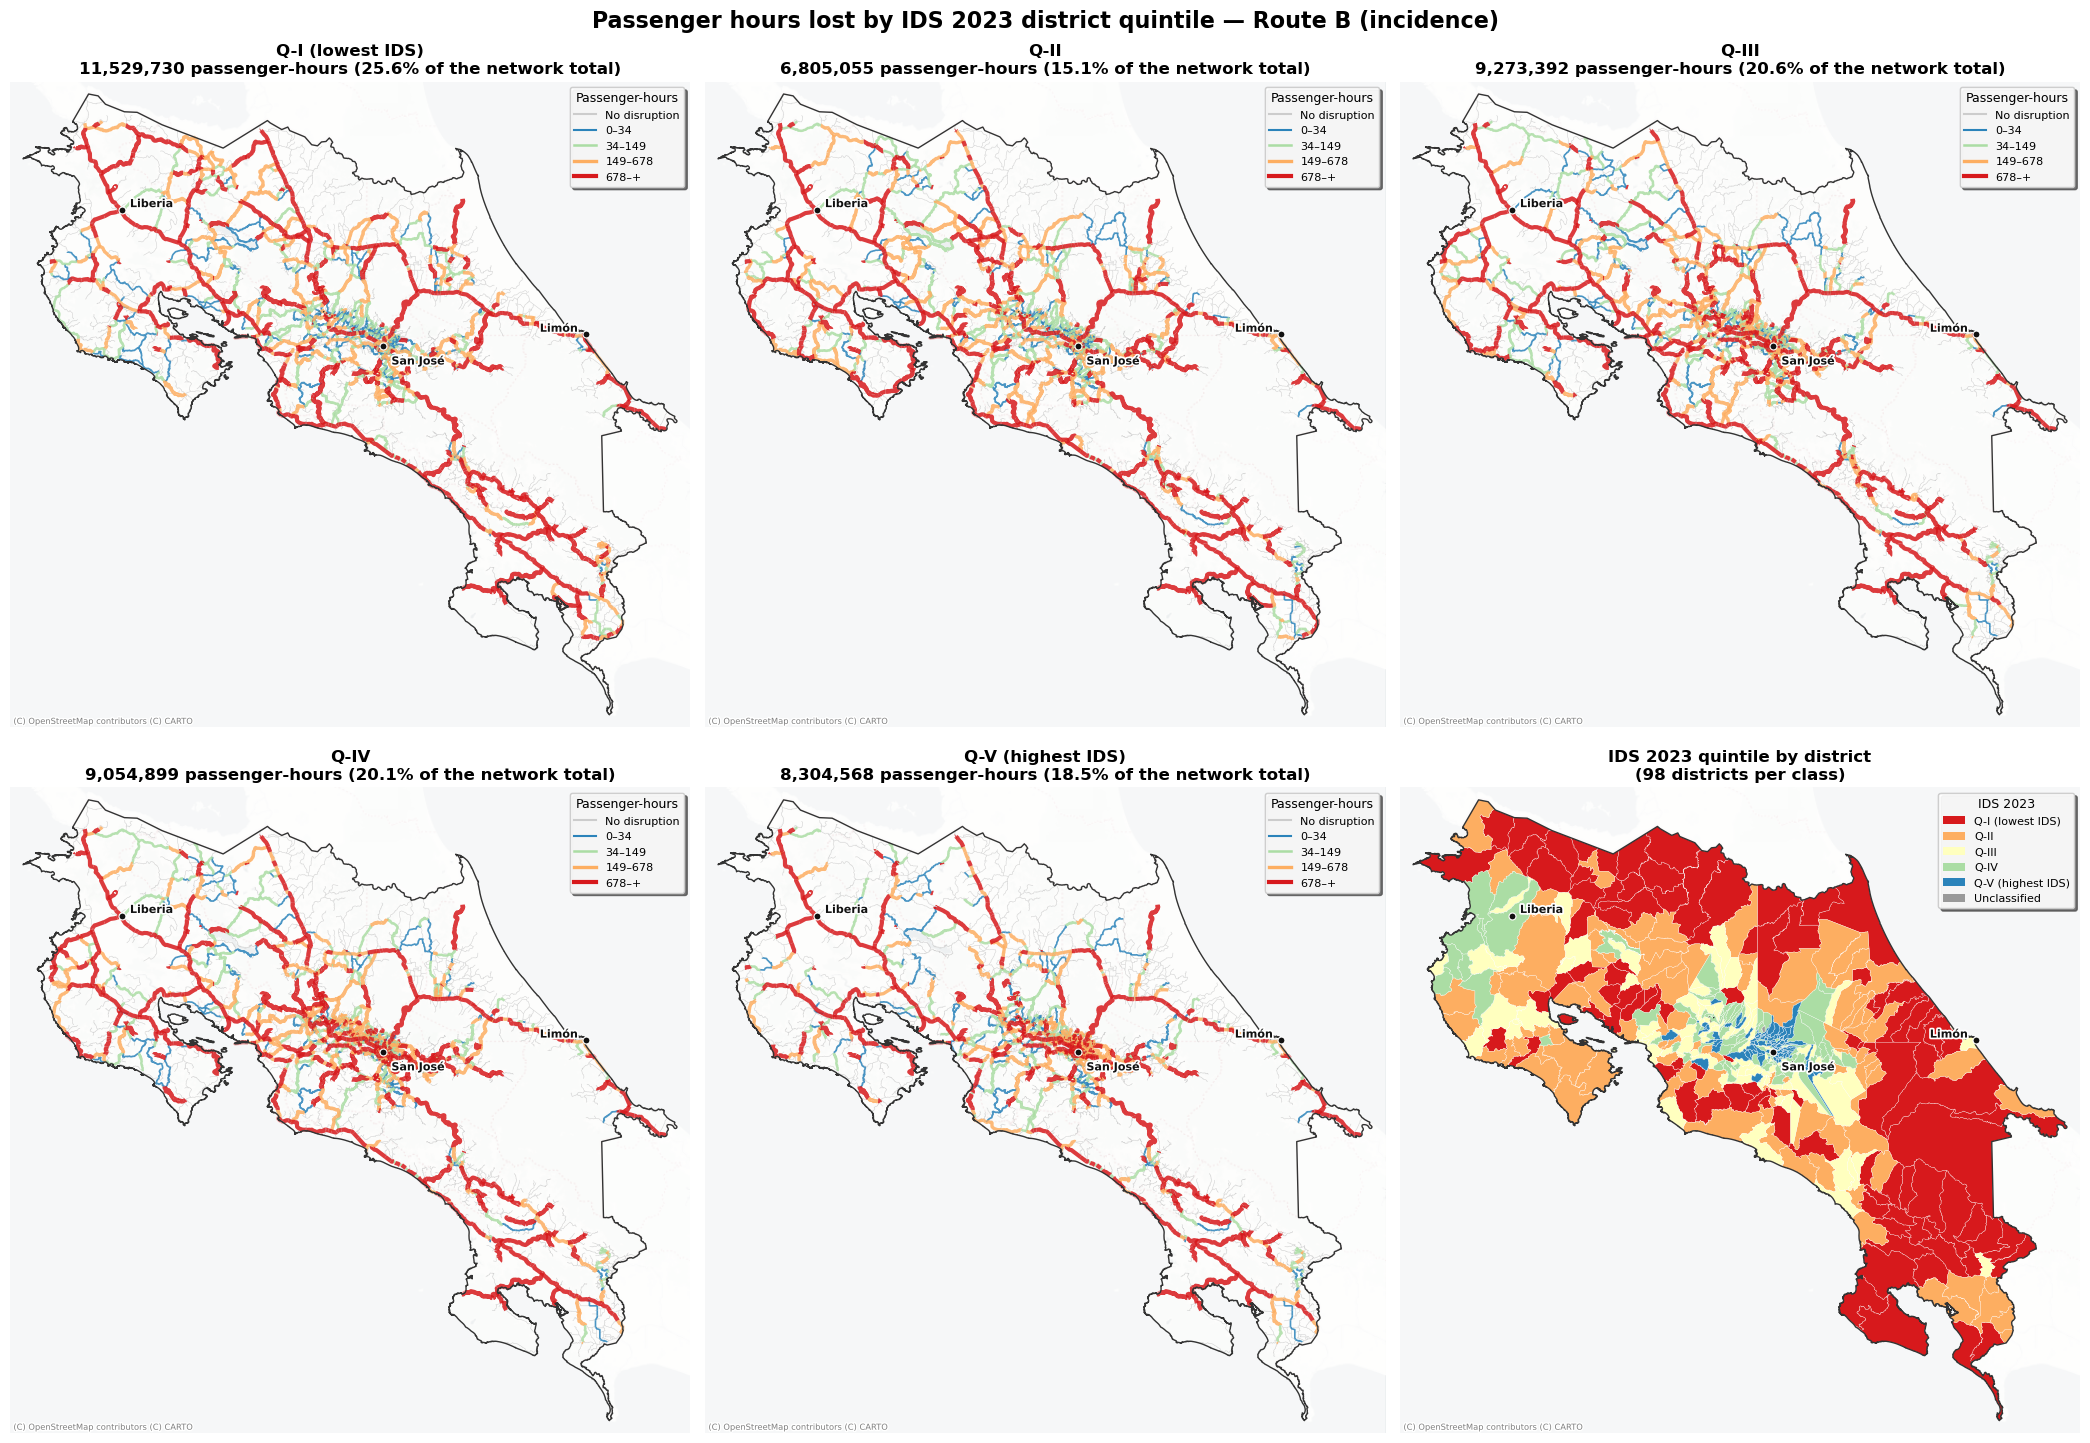

Class breaks: ['0', '34', '149', '678', '+']


In [21]:
def plot_quintile_panels(metric, route, title, legend_title, outfile):
    """Five map panels (one per IDS quintile) plus an IDS context panel, shared breaks."""
    cols = metric_cols(metric, route)[:5]          # the unclassified class is not mapped
    pooled = np.concatenate([socio[c].to_numpy(dtype=float) for c in cols])
    breaks = data_driven_breaks(pooled)

    fig, axes = plt.subplots(2, 3, figsize=(21, 15), facecolor="white")
    for ax, col, name in zip(axes.ravel()[:5], cols, QNAMES[:5]):
        classes, labels = classify_metric(socio_web[col], breaks)
        for i, label in enumerate(labels):
            subset = socio_web[classes == label]
            if len(subset) == 0:
                continue
            subset.plot(ax=ax, color=CLASS_COLORS[i], linewidth=CLASS_WIDTHS[i],
                        alpha=0.85, zorder=2 + i)
        total = socio[col].sum()
        ax.set_title(f"{name}\n{total:,.0f} {legend_title.lower()} "
                     f"({100 * total / socio[metric].sum():.1f}% of the network total)",
                     fontsize=12, fontweight="bold")
        handles = [Line2D([0], [0], color=CLASS_COLORS[i], lw=max(CLASS_WIDTHS[i], 1.5),
                          label=labels[i]) for i in range(len(labels))]
        style_cr_map(ax, 3857, legend_handles=handles, legend_title=legend_title,
                     legend_kw=dict(fontsize=8, title_fontsize=9), city_fontsize=8)

    # Context panel: the districts themselves.
    ax = axes.ravel()[5]
    for q, colour, name in zip(["I", "II", "III", "IV", "V"], QCOLORS[:5], QNAMES[:5]):
        sub = ids_web[ids_web["QUINTIL"] == q]
        if len(sub):
            sub.plot(ax=ax, color=colour, edgecolor="white", linewidth=0.2, zorder=2)
    missing = ids_web[ids_web["QUINTIL"].isna()]
    if len(missing):
        missing.plot(ax=ax, color=QCOLORS[5], edgecolor="white", linewidth=0.2, zorder=2)
    ax.set_title("IDS 2023 quintile by district\n(98 districts per class)",
                 fontsize=12, fontweight="bold")
    # style_cr_map frames on the mainland. Isla del Coco sits ~500 km offshore and would
    # otherwise shrink the mainland to a smudge in this panel alone.
    style_cr_map(ax, 3857,
                 legend_handles=[Patch(facecolor=c, label=n) for c, n in zip(QCOLORS, QNAMES)],
                 legend_title="IDS 2023", legend_kw=dict(fontsize=8, title_fontsize=9), city_fontsize=8)

    fig.suptitle(f"{title} — {HEADLINE}", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.savefig(figure_path / outfile, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Class breaks: {[fmt_break(b) for b in breaks]}")


plot_quintile_panels("phl", MAP_PREFIX, "Passenger hours lost by IDS 2023 district quintile",
                     "Passenger-hours", "SPOF_PHL_by_IDS_quintile.png")

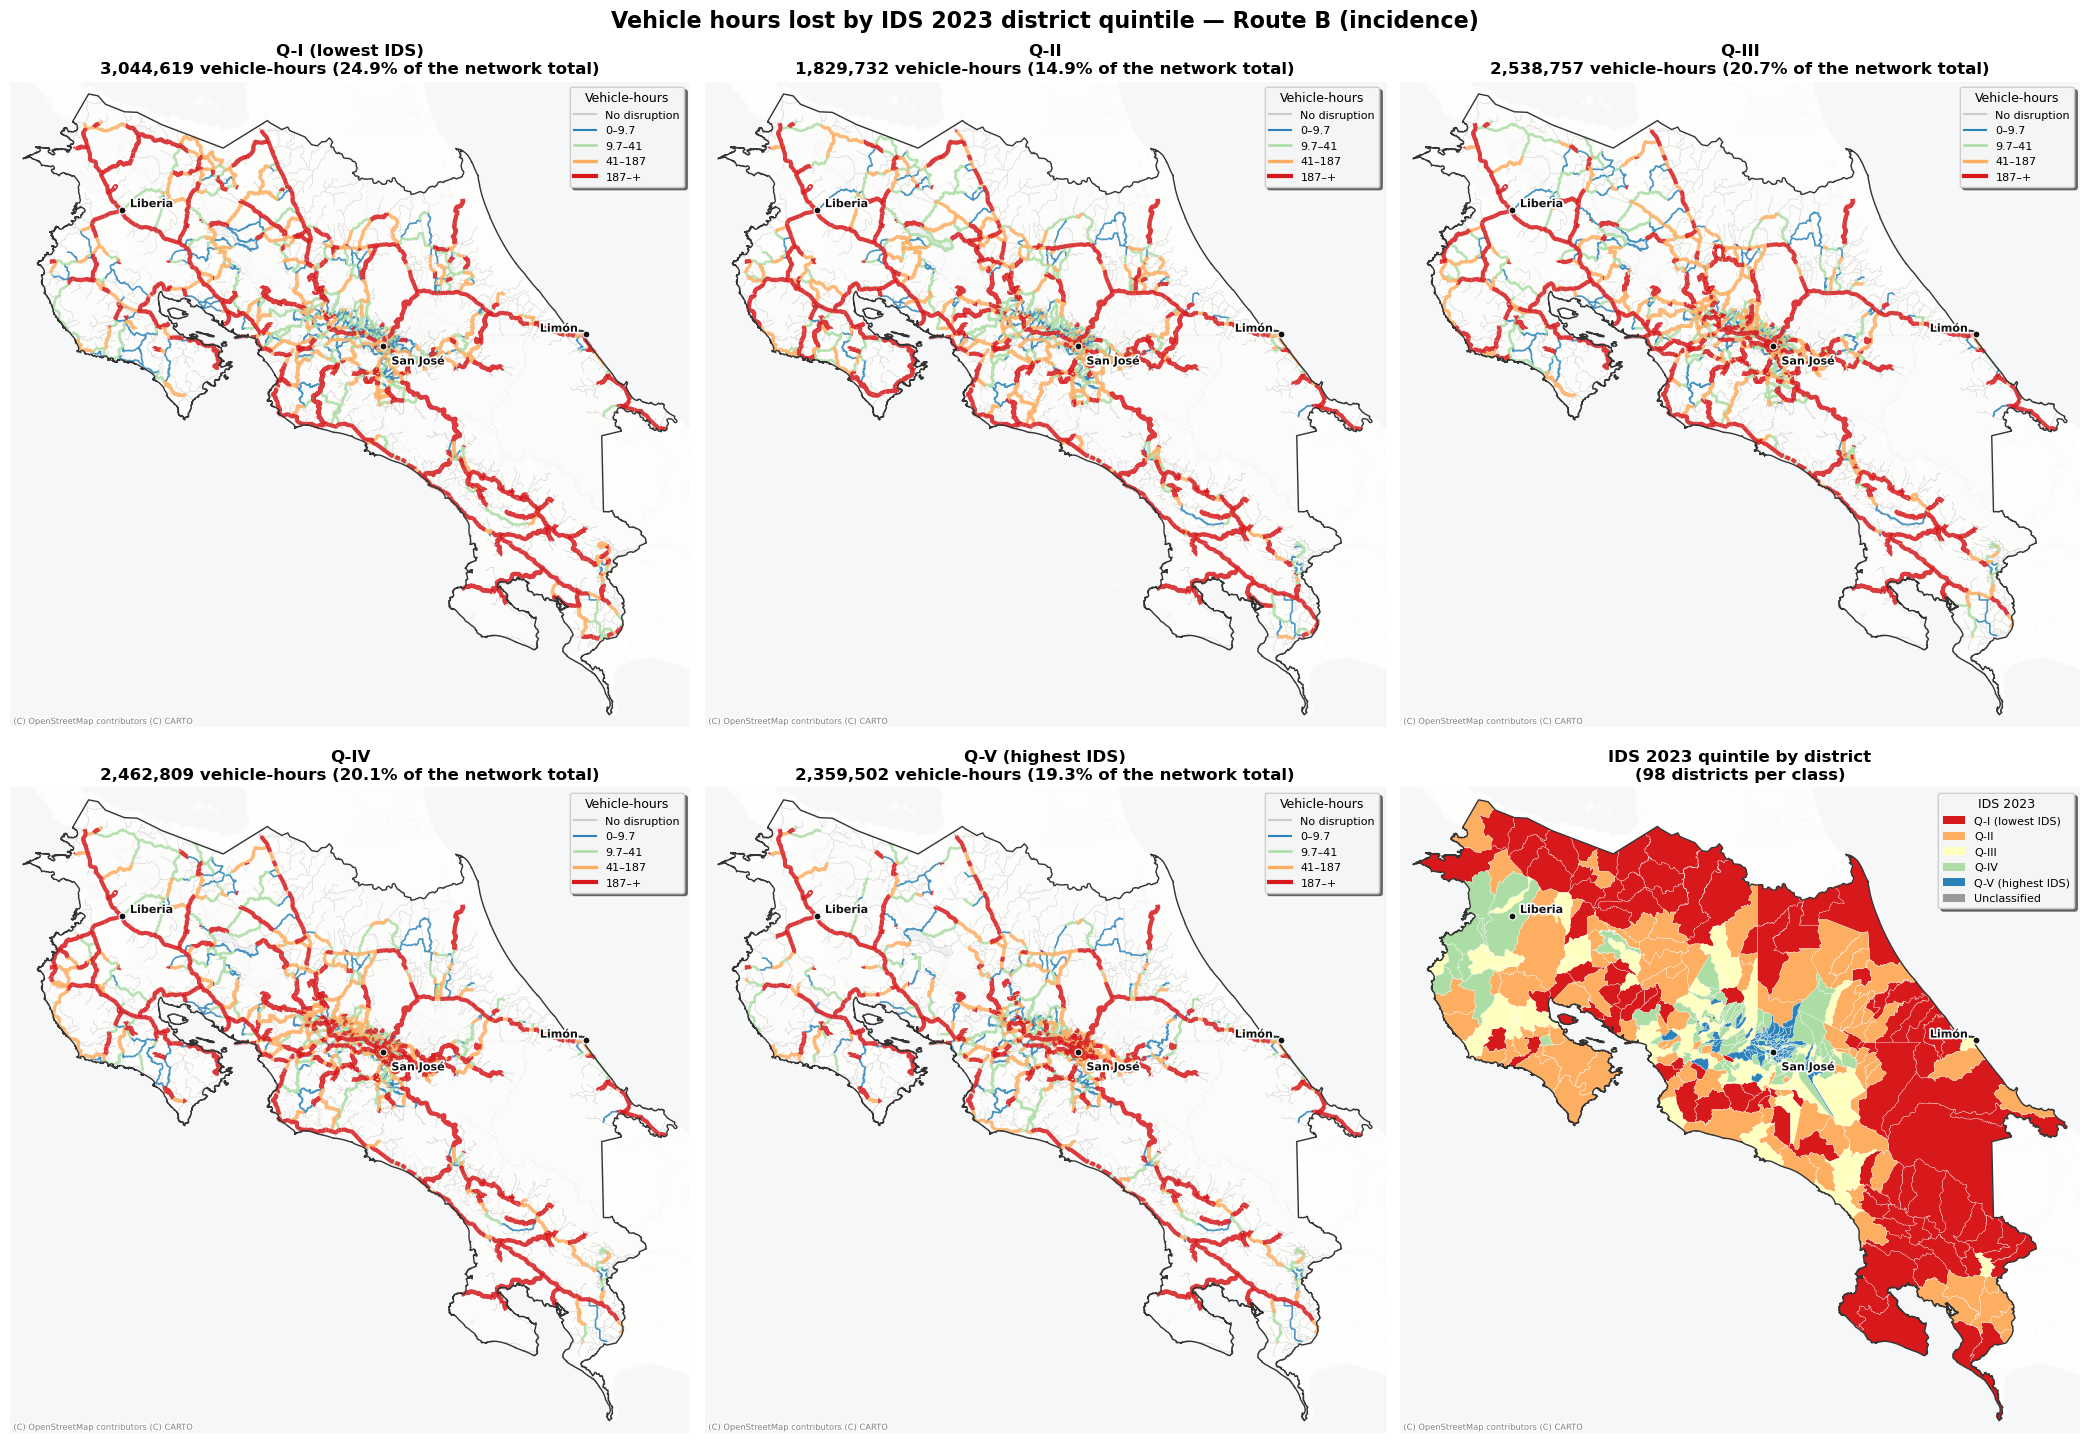

Class breaks: ['0', '9.7', '41', '187', '+']


In [22]:
plot_quintile_panels("vhl", MAP_PREFIX, "Vehicle hours lost by IDS 2023 district quintile",
                     "Vehicle-hours", "SPOF_VHL_by_IDS_quintile.png")

## 11. Equity summary
A raw quintile share of PHL is not interpretable on its own, because the quintiles hold equal
numbers of *districts* but very different numbers of *people*. The location quotient

```
LQ_q = (share of PHL borne by q) / (share of population in q)
```

is the number that supports an equity claim: `LQ > 1` means the quintile bears more disruption
than its population share.

In [23]:
def equity_table(metric, route):
    cols = metric_cols(metric, route)
    totals = np.array([socio[c].sum() for c in cols], dtype=float)
    share = totals / totals.sum()
    with np.errstate(invalid="ignore", divide="ignore"):
        lq = np.where(pop_share > 0, share / pop_share, np.nan)
    return pd.DataFrame(
        {f"{metric}": totals, "share_%": 100 * share, "pop_share_%": 100 * pop_share, "LQ": lq},
        index=QNAMES,
    )


for m in SPLIT_METRICS:
    print(f"\n{m.upper()} by IDS quintile — {HEADLINE}")
    print(equity_table(m, MAP_PREFIX).round(3).to_string())


PHL by IDS quintile — Route B (incidence)
                            phl  share_%  pop_share_%     LQ
Q-I (lowest IDS)   1.152973e+07   25.628       11.296  2.269
Q-II               6.805055e+06   15.126       14.371  1.053
Q-III              9.273392e+06   20.613       20.734  0.994
Q-IV               9.054899e+06   20.127       28.655  0.702
Q-V (highest IDS)  8.304568e+06   18.459       24.851  0.743
Unclassified       2.135236e+04    0.047        0.093  0.508

VHL by IDS quintile — Route B (incidence)
                           vhl  share_%  pop_share_%     LQ
Q-I (lowest IDS)   3044619.035   24.872       11.296  2.202
Q-II               1829731.945   14.947       14.371  1.040
Q-III              2538756.682   20.739       20.734  1.000
Q-IV               2462808.843   20.119       28.655  0.702
Q-V (highest IDS)  2359501.932   19.275       24.851  0.776
Unclassified          5784.492    0.047        0.093  0.506

PKL by IDS quintile — Route B (incidence)
                        

In [24]:
if HAS_EXACT:
    a = equity_table("phl", "flow")[["share_%", "LQ"]].rename(
        columns={"share_%": "A_share_%", "LQ": "A_LQ"})
    b = equity_table("phl", "exact")[["share_%", "LQ"]].rename(
        columns={"share_%": "B_share_%", "LQ": "B_LQ"})
    comp = a.join(b)
    comp["share_shift_pp"] = comp["B_share_%"] - comp["A_share_%"]
    print("Route A (exposure) vs Route B (incidence), PHL:")
    print(comp.round(3).to_string())
    print("\nA positive shift means the quintile bears MORE of the disruption once the "
          "delay each group actually suffers is measured, rather than assumed equal.")

    # Mean delay per quintile, demand-weighted across the whole network.
    print("\nNetwork mean delay when a road fails, by origin quintile (minutes):")
    for k, (c, name) in enumerate(zip(QCOLS, QNAMES)):
        num = socio[num_cols[k]].sum()
        den = socio[den_cols[k]].sum()
        print(f"  {name:20} {60 * num / den if den > 0 else 0:7.1f}")

Route A (exposure) vs Route B (incidence), PHL:
                   A_share_%   A_LQ  B_share_%   B_LQ  share_shift_pp
Q-I (lowest IDS)      26.043  2.306     25.628  2.269          -0.415
Q-II                  15.103  1.051     15.126  1.053           0.023
Q-III                 20.622  0.995     20.613  0.994          -0.010
Q-IV                  20.136  0.703     20.127  0.702          -0.010
Q-V (highest IDS)     18.040  0.726     18.459  0.743           0.419
Unclassified           0.056  0.595      0.047  0.508          -0.008

A positive shift means the quintile bears MORE of the disruption once the delay each group actually suffers is measured, rather than assumed equal.

Network mean delay when a road fails, by origin quintile (minutes):
  Q-I (lowest IDS)        49.1
  Q-II                    27.9
  Q-III                   26.6
  Q-IV                    19.6
  Q-V (highest IDS)       17.4
  Unclassified            15.5


### What the A-vs-B comparison shows
Two numbers to read together, because they say different things.

**The shares barely move.** Q-I goes from 26.0% (Route A) to 25.6% (Route B); every quintile
shifts by less than half a percentage point. So the equal-delay assumption inside Route A is
close to harmless *at road level*: on any single road, the quintiles that use it suffer
near-proportional delay.

**The network-level delay gap is large.** A trip originating in Q-I waits about **49 minutes**
when a road fails, against **17 minutes** for Q-V — a factor of 2.8.

These are consistent, and together they locate the inequity. It is almost entirely an **exposure**
effect: low-IDS districts depend on roads whose failure is expensive — long detours, few
alternatives, isolation — rather than suffering worse treatment on the roads everyone shares. That
is a stronger and more actionable finding than a within-road differential would have been, because
it points at network redundancy in specific corridors rather than at a diffuse gradient.

Practical consequence: for this network, Route A is a sound approximation and can be used when the
percolation cache is unavailable. Do not generalise that to a different network without re-running
the check — it is a property of this topology, not a theorem.

In [25]:
# Which quintile bears most of each road's PHL, and how concentrated that is.
head_cols = metric_cols("phl", MAP_PREFIX)[:5]
head = socio[head_cols].to_numpy(dtype=float)
row_tot = head.sum(axis=1)

socio["dominant_quintile"] = np.where(
    row_tot > 0, np.array(QCOLS[:5])[np.argmax(head, axis=1)], "none"
)
socio["dominant_share"] = np.where(row_tot > 0, head.max(axis=1) / row_tot, np.nan)

summary = (socio[socio["dominant_quintile"] != "none"]
           .groupby("dominant_quintile")
           .agg(roads=("physical_edge_id", "count"),
                length_km=("road_length", "sum"),
                phl=("phl", "sum"),
                mean_dominant_share=("dominant_share", "mean"))
           .reindex(QCOLS[:5]))
summary.index = QNAMES[:5]
print("Roads by the quintile that bears most of their PHL:")
print(summary.round(2).to_string())

print("\nTop 10 roads by PHL borne by the lowest quintile (Q-I):")
q1 = metric_cols("phl", MAP_PREFIX)[0]
print(socio.nlargest(10, q1)[["physical_edge_id", "NOMBRE", "CLASE", "total_aadt", "phl",
                              q1, "dominant_quintile"]]
      .to_string(index=False))

Roads by the quintile that bears most of their PHL:
                   roads  length_km          phl  mean_dominant_share
Q-I (lowest IDS)     596    2531.72  19062771.70                 0.53
Q-II                 527    2136.20   6697653.08                 0.50
Q-III                510    1351.24   9491036.49                 0.48
Q-IV                 812    1470.30   6453164.30                 0.49
Q-V (highest IDS)    578     440.98   3284371.44                 0.60

Top 10 roads by PHL borne by the lowest quintile (Q-I):
 physical_edge_id                NOMBRE     CLASE  total_aadt           phl  phl_exact_q1 dominant_quintile
             2199  Ruta Nacional No. 32  Primaria     14779.0 967738.481484 328062.415526                q1
             2200  Ruta Nacional No. 32  Primaria     14779.0 967738.481484 328062.415526                q1
             2201  Ruta Nacional No. 32  Primaria     14779.0 964957.772816 315539.680556                q1
             1265  Ruta Nacional No. 36

In [26]:
# Same split by road class, since the policy lever is usually class-specific.
class_order = [c for c in ["Primaria", "Secundaria", "Terciaria", "Local", "Sin clasificar"]
               if c in socio["CLASE"].unique()]
by_class = socio.groupby("CLASE")[metric_cols("phl", MAP_PREFIX)[:5]].sum().reindex(class_order)
by_class.columns = QNAMES[:5]
pct = 100 * by_class.div(by_class.sum(axis=1), axis=0)
print("Share of PHL by IDS quintile within each road class (%):")
print(pct.round(1).to_string())

Share of PHL by IDS quintile within each road class (%):
                Q-I (lowest IDS)  Q-II  Q-III  Q-IV  Q-V (highest IDS)
CLASE                                                                 
Primaria                    24.2  14.4   24.1  15.6               21.7
Secundaria                  26.7  20.7   16.2  19.7               16.8
Terciaria                   32.1  16.4   22.4  15.6               13.5
Local                       25.3  13.8   16.1  29.0               15.8
Sin clasificar              20.1  30.2   19.9  18.6               11.1


## 12. Save results

In [27]:
id_cols = ["physical_edge_id", "NOMBRE", "CLASE", "ID_TRAMO", "ID_RUTA", "ADMIN",
           "road_length", "speed", "total_aadt", "aadt_imputed",
           "pct_isolated", "pct_unaffected", "pct_delayed",
           "average_time_disruption", "average_dist_disruption",
           "phl", "vhl", "pkl"]
share_out = ([f"flow_mod_{c}" for c in QCOLS] + [f"share_{c}" for c in QCOLS]
             + [f"aadt_{c}" for c in QCOLS] + [f"pct_aadt_{c}" for c in QCOLS])
route_a_out = [f"{m}_{c}" for m in SPLIT_METRICS for c in QCOLS]
route_b_out = ([f"{m}_exact_{c}" for m in SPLIT_METRICS for c in QCOLS]
               + [f"beta_{c}" for c in QCOLS] + [f"delay_min_{c}" for c in QCOLS]) \
    if HAS_EXACT else []

out_cols = (id_cols + share_out + route_a_out + route_b_out
            + ["dominant_quintile", "dominant_share", "geometry"])
missing = [c for c in out_cols if c not in socio.columns]
assert not missing, f"missing output columns: {missing}"

out = socio[out_cols].copy()
out["attribution_rule"] = ATTRIBUTION_RULE
out["headline_route"] = HEADLINE
out = gpd.GeoDataFrame(out, geometry="geometry", crs=socio.crs)

directed_out_cols = (["id", "physical_edge_id", "from_id", "to_id", "direction_side",
                      "NOMBRE", "CLASE", "road_length", "total_aadt", "phl", "vhl", "pkl"]
                     + [f"share_{c}" for c in QCOLS] + [f"aadt_{c}" for c in QCOLS]
                     + [f"pct_aadt_{c}" for c in QCOLS] + route_a_out + ["geometry"])
dout = gpd.GeoDataFrame(dres[directed_out_cols].copy(), geometry="geometry", crs=dres.crs)

# Rewrite from scratch: mode="w" on an existing GeoPackage replaces the dataset, so
# the second layer has to be appended rather than written.
if socio_results_path.exists():
    socio_results_path.unlink()
out.to_file(socio_results_path, layer="physical_by_quintile", driver="GPKG")
dout.to_file(socio_results_path, layer="directed_by_quintile", driver="GPKG", mode="a")

print(f"Written : {socio_results_path.relative_to(BASE_DIR)}")
print(f"  physical_by_quintile : {len(out):,} rows, {len(out.columns)} columns")
print(f"  directed_by_quintile : {len(dout):,} rows, {len(dout.columns)} columns")

Written : intermediate_results/gpkg/travel_disruptions/socioeconomic_criticality.gpkg
  physical_by_quintile : 5,012 rows, 95 columns
  directed_by_quintile : 9,764 rows, 49 columns


In [28]:
# Re-open and verify the round trip.
check = gpd.read_file(socio_results_path, layer="physical_by_quintile")
assert len(check) == len(socio), f"row count mismatch: {len(check)} vs {len(socio)}"
assert check.crs.to_epsg() == WORKING_EPSG, f"CRS mismatch: {check.crs}"
assert check["physical_edge_id"].is_unique, "duplicate roads in output"

recomposed = check[metric_cols("phl", MAP_PREFIX)].sum(axis=1)
assert np.allclose(recomposed, check["phl"].where(check["phl"] > 0, recomposed),
                   rtol=1e-6, atol=1e-4), "PHL split does not reconcile after round trip"

print("Output manifest")
print("=" * 64)
print(f"Path       : {socio_results_path}")
print(f"Rows       : {len(check):,}")
print(f"Attribution: {ATTRIBUTION_RULE}")
print(f"Headline   : {HEADLINE}")
print(f"Size       : {socio_results_path.stat().st_size / 1e6:.1f} MB")
print(f"Caches     : {flow_cache_path.name}"
      + (f", {disruption_cache_path.name}" if HAS_EXACT else ""))
print("\nFigures:")
for f in ["SPOF_PHL_by_IDS_quintile.png", "SPOF_VHL_by_IDS_quintile.png"]:
    p = figure_path / f
    print(f"  {f} : {'written' if p.exists() else 'MISSING'}")

Output manifest
Path       : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/travel_disruptions/socioeconomic_criticality.gpkg
Rows       : 5,012
Attribution: origin
Headline   : Route B (incidence)
Size       : 139.5 MB
Caches     : od_quintile_flow.parquet, quintile_disruption.parquet

Figures:
  SPOF_PHL_by_IDS_quintile.png : written
  SPOF_VHL_by_IDS_quintile.png : written


## 13. Assumptions and limitations

1. **Trip production per capita is income-independent.** The gravity mass is population, so a
   district's trip production scales with headcount alone. Real trip rates and car ownership
   rise steeply with income, which means this model **overstates the low quintiles' share of
   vehicle flow and understates the high quintiles'**. The sign is known, the magnitude is not.
   Correcting it needs an income-dependent trip rate from a real source (ENAHO mobility data or
   the vehicle registry); `INDICE_ECO` would be a crude stand-in.
2. **IDS is not income.** It is a five-dimension composite — economic, electoral participation,
   health, education, security. Results should be described as "districts ranked by social
   development", never as income groups. See `MD/district_income_shares_CR.md` for what an
   income-share estimate would actually require.
3. **One population point per district.** Inherited from notebook 2, but it bites harder here:
   the low-IDS districts are the large rural ones, so precisely the population whose equity is
   being measured is the most spatially misplaced.
4. **Composition modelled, magnitude observed.** Quintile shares come from the gravity
   assignment; the totals they divide come from observed AADT. Where modelled and observed flow
   disagree strongly on a segment, the split is only as good as the routing model.
5. **Freight is excluded on purpose.** `thl`/`tkl` are not split: freight OD is not
   population-driven, so charging tonne-hours to the resident quintiles of the districts a
   corridor passes would produce a number that gets quoted and cannot be defended.
6. **The isolation penalty drives the low-quintile result.** Pairs left with no route take
   `2 × the longest baseline trip`, and those pairs are disproportionately remote and low-IDS.
   `beta_noiso_*` in the Route B cache gives the split with isolated pairs removed; report both
   if the equity conclusion depends on it.
7. **Unclassified population.** Three localities (0.22% of the population) have no published
   quintile — two are post-IDS district splits resolved spatially, one (Puente Salas) is a
   genuine IDS data gap. They are carried as an explicit class, never imputed into Q-I.